# Week 2: Lasso, Ridge, and Elastic Net Regression
**Rupal Paliwal, Mod C, Semester 1**

**Dataset:** Movies Box Office 2000 to 2024 (Kaggle), 5,000 top grossing films. This is the primary dataset from my capstone proposal (*Movie Consumer Behavior & Film Profitability Analysis*).

**Question:** Which film characteristics actually matter for predicting worldwide box office revenue, and does regularization help?

**Plan:** fit a plain linear regression as a baseline, then lasso, ridge, and elastic net, and compare their accuracy and coefficients.

**Part 1** uses the box office data. **Part 2** adds the other two project datasets, MovieLens 20M and the 4 Services Streaming catalogs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, ElasticNetCV, lasso_path, Ridge
from sklearn.metrics import r2_score, mean_squared_error

## 1. Load the data

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')
print(df.shape)
df.head()

(5000, 13)


,Rank,Release Group,$Worldwide,$Domestic,Domestic %,$Foreign,Foreign %,Year,Genres,Rating,Vote_Count,Original_Language,Production_Countries
0,1,Mission: Impossible II,546388108.0,215409889.0,39.4,330978219.0,60.6,2000,"Adventure, Action, Thriller",6.126/10,6741.0,en,United States of America
1,2,Gladiator,460583960.0,187705427.0,40.8,272878533.0,59.2,2000,"Action, Drama, Adventure",8.217/10,19032.0,en,"United Kingdom, United States of America"
2,3,Cast Away,429632142.0,233632142.0,54.4,196000000.0,45.6,2000,"Adventure, Drama",7.663/10,11403.0,en,United States of America
3,4,What Women Want,374111707.0,182811707.0,48.9,191300000.0,51.1,2000,"Comedy, Romance",6.45/10,3944.0,en,"United Kingdom, United States of America"
4,5,Dinosaur,349822765.0,137748063.0,39.4,212074702.0,60.6,2000,"Animation, Family, Adventure",6.544/10,2530.0,en,United States of America


## 2. Prepare features

- **Target:** `log($Worldwide)`. Revenue is heavily right skewed (mean ≈ \$119M vs. median ≈ \$48M), so I model it on a log scale.
- **Numeric features:** `log(Vote_Count)`, `Rating` (converted from strings like `'8.217/10'`), and `Year`.
- **Genres:** multi hot encoded (a film can have several genres).
- **Language:** one hot for the 10 most common languages, everything else grouped as `other`. English is the reference category and is dropped.
- **Excluded on purpose:** `$Domestic`, `$Foreign`, `Domestic %`, `Foreign %`. Worldwide gross is literally domestic + foreign, so including them would leak the answer and produce a meaningless R².
- Rows missing rating, votes, genres, or language are dropped (about 3 to 4% of the data). A rating of exactly 0 means "no rating," so those rows are dropped too.

In [3]:
data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

# Target
y = np.log(data['$Worldwide'])

# Numeric features
X = pd.DataFrame({
    'log_votes': np.log1p(data['Vote_Count']),
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

# Genres (multi-hot)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')

# Language (top 10, rest = other; English is the reference)
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
print('Rows:', X.shape[0], '| Features:', X.shape[1])
X.head()

Rows: 4803 | Features: 32


,log_votes,rating,year,genre_Action,genre_Adventure,genre_Animation,genre_Comedy,genre_Crime,genre_Documentary,genre_Drama,...,lang_cn,lang_de,lang_es,lang_fr,lang_hi,lang_it,lang_ja,lang_ko,lang_other,lang_zh
0,8.816112,6.126,2000,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9.853930,8.217,2000,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,9.341719,7.663,2000,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,8.280204,6.450,2000,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7.836370,6.544,2000,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Train/test split and scaling

Regularization penalizes the *size* of coefficients, so every feature has to be on the same scale first. Otherwise a feature measured in large units (like `year`) would get a tiny coefficient and escape the penalty for no real reason. I put `StandardScaler` inside a pipeline so the scaler is fit only on the training data.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (3842, 32) | Test: (961, 32)


## 4. Baseline: plain linear regression (no regularization)

In [5]:
def evaluate(name, model):
    pred = model.predict(X_test)
    return {'model': name,
            'test_R2': r2_score(y_test, pred),
            'test_RMSE_log': np.sqrt(mean_squared_error(y_test, pred))}

ols = make_pipeline(StandardScaler(), LinearRegression())
ols.fit(X_train, y_train)

results = [evaluate('OLS (no regularization)', ols)]
pd.DataFrame(results)

,model,test_R2,test_RMSE_log
0,OLS (no regularization),0.525604,0.795776


## 5. Lasso regression (L1 penalty)

Lasso adds λ × (sum of |coefficients|) to the error. I pick λ with 5 fold cross validation over a logarithmic grid, as the lesson suggests.

*Note on names:* sklearn calls the lesson's λ `alpha`.

In [6]:
lasso = make_pipeline(StandardScaler(),
                      LassoCV(alphas=np.logspace(-4, 0, 50), cv=5, max_iter=50000))
lasso.fit(X_train, y_train)

lasso_model = lasso[-1]
print('Best lambda (alpha):', round(lasso_model.alpha_, 5))
print('Features kept:', (lasso_model.coef_ != 0).sum(), 'of', X.shape[1])
print('Features dropped (coefficient = 0):')
print([f for f, c in zip(X.columns, lasso_model.coef_) if c == 0])

results.append(evaluate('Lasso', lasso))

Best lambda (alpha): 0.00356
Features kept: 30 of 32
Features dropped (coefficient = 0):
['genre_Mystery', 'lang_other']


## 6. Ridge regression (L2 penalty)

Ridge adds λ × (sum of squared coefficients). It shrinks coefficients but does not push them all the way to zero.

In [7]:
ridge = make_pipeline(StandardScaler(),
                      RidgeCV(alphas=np.logspace(-2, 4, 50), cv=5))
ridge.fit(X_train, y_train)

ridge_model = ridge[-1]
print('Best lambda (alpha):', round(ridge_model.alpha_, 3))
print('Features kept:', (ridge_model.coef_ != 0).sum(), 'of', X.shape[1])

results.append(evaluate('Ridge', ridge))

Best lambda (alpha): 15.264
Features kept: 32 of 32


## 7. Elastic net (mix of L1 and L2)

Elastic net blends the two penalties. The mixing parameter (called "alpha" in the lesson) is `l1_ratio` in sklearn: 1 = pure lasso, 0 = pure ridge. I let cross validation choose both the mix and λ.

In [8]:
enet = make_pipeline(StandardScaler(),
                     ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],
                                  alphas=np.logspace(-4, 0, 50), cv=5, max_iter=50000))
enet.fit(X_train, y_train)

enet_model = enet[-1]
print('Best l1_ratio:', enet_model.l1_ratio_)
print('Best lambda (alpha):', round(enet_model.alpha_, 5))
print('Features kept:', (enet_model.coef_ != 0).sum(), 'of', X.shape[1])

results.append(evaluate('Elastic net', enet))

Best l1_ratio: 0.9
Best lambda (alpha): 0.00429
Features kept: 30 of 32


## 8. Compare the models

In [9]:
summary = pd.DataFrame(results)
summary['features_kept'] = [X.shape[1],
                            (lasso_model.coef_ != 0).sum(),
                            (ridge_model.coef_ != 0).sum(),
                            (enet_model.coef_ != 0).sum()]
summary.round(4)

,model,test_R2,test_RMSE_log,features_kept
0,OLS (no regularization),0.5256,0.7958,32
1,Lasso,0.5271,0.7946,30
2,Ridge,0.5263,0.7952,32
3,Elastic net,0.5271,0.7945,30


Coefficients side by side (on standardized features, so they are directly comparable):

In [10]:
coefs = pd.DataFrame({
    'OLS': ols[-1].coef_,
    'Lasso': lasso_model.coef_,
    'Ridge': ridge_model.coef_,
    'ElasticNet': enet_model.coef_,
}, index=X.columns)

coefs.sort_values('OLS', key=abs, ascending=False).round(3)

,OLS,Lasso,Ridge,ElasticNet
log_votes,0.966,0.939,0.952,0.935
lang_zh,0.352,0.340,0.346,0.338
lang_ja,0.147,0.127,0.139,0.125
lang_fr,-0.147,-0.145,-0.147,-0.145
genre_Family,0.115,0.104,0.114,0.103
rating,-0.084,-0.069,-0.079,-0.067
lang_ko,0.083,0.070,0.078,0.069
genre_Horror,-0.079,-0.070,-0.078,-0.070
lang_it,-0.078,-0.075,-0.078,-0.074
genre_Drama,-0.077,-0.072,-0.077,-0.072


## 9. How λ changes the coefficients

This plot shows the core difference between the two penalties. As λ grows (moving right), lasso coefficients hit **exactly zero** one by one, while ridge coefficients shrink smoothly toward zero but never reach it.

*(The λ values on the two panels aren't directly comparable because sklearn scales the lasso and ridge objectives differently.)*

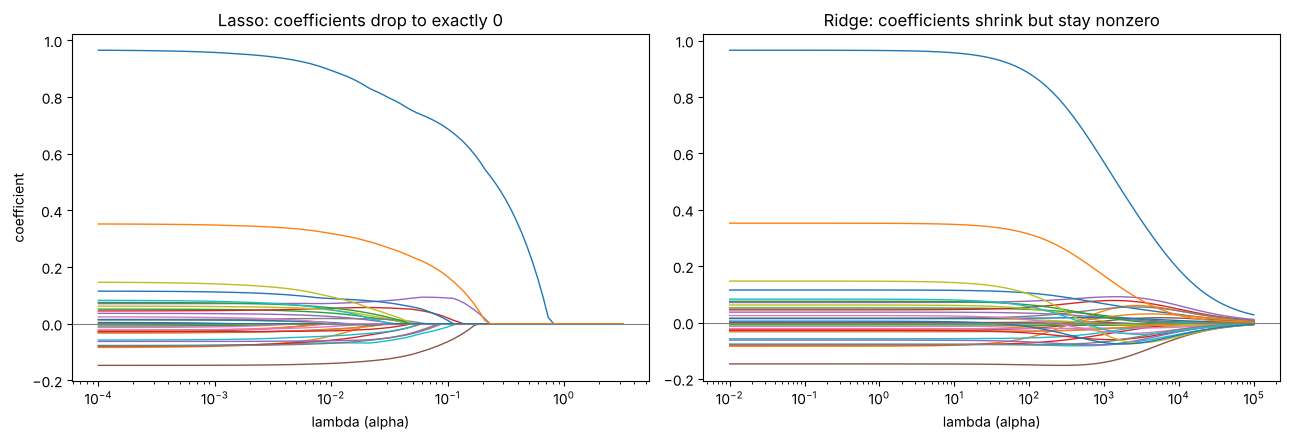

In [11]:
X_train_s = StandardScaler().fit_transform(X_train)

# Lasso path
lasso_alphas, lasso_coefs, _ = lasso_path(X_train_s, y_train - y_train.mean(),
                                          alphas=np.logspace(-4, 0.5, 100))

# Ridge path
ridge_alphas = np.logspace(-2, 5, 100)
ridge_coefs = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in ridge_alphas]).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for row in lasso_coefs:
    axes[0].plot(lasso_alphas, row, linewidth=1)
axes[0].set_xscale('log'); axes[0].set_title('Lasso: coefficients drop to exactly 0')
axes[0].set_xlabel('lambda (alpha)'); axes[0].set_ylabel('coefficient')

for row in ridge_coefs:
    axes[1].plot(ridge_alphas, row, linewidth=1)
axes[1].set_xscale('log'); axes[1].set_title('Ridge: coefficients shrink but stay nonzero')
axes[1].set_xlabel('lambda (alpha)')

for ax in axes:
    ax.axhline(0, color='grey', linewidth=0.8)
plt.tight_layout()
plt.show()

## 10. Lasso as feature selection: pushing λ higher

The cross validated λ is small, so lasso only drops a couple of features. To see which features *really* matter, I refit lasso with larger λ values and track how many features survive and how much accuracy is lost.

In [12]:
from sklearn.linear_model import Lasso

rows = []
for lam in [lasso_model.alpha_, 0.02, 0.05, 0.1, 0.3]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=lam, max_iter=50000)).fit(X_train, y_train)
    kept = [f for f, c in zip(X.columns, m[-1].coef_) if c != 0]
    rows.append({'lambda': round(lam, 4),
                 'features_kept': len(kept),
                 'test_R2': round(r2_score(y_test, m.predict(X_test)), 4),
                 'surviving_features': ', '.join(kept) if len(kept) <= 8 else '(too many to list)'})

pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows)

,lambda,features_kept,test_R2,surviving_features
0,0.0036,30,0.5271,(too many to list)
1,0.0200,23,0.5220,(too many to list)
2,0.0500,13,0.4960,(too many to list)
3,0.1000,7,0.4632,"log_votes, genre_Action, genre_Adventure, genre_Drama, genre_Family, lang_fr, lang_zh"
4,0.3000,1,0.3285,log_votes


# Part 2: All Three Project Datasets

My project has three datasets: the box office data used above, **MovieLens 20M** (user ratings, tags, and the tag genome), and the **4 Services Streaming** catalogs (Netflix, Prime Video, Hulu, Disney+). `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb` joins them by cleaned title and release year and saves `combined_films.csv`.

MovieLens 20M ends in 2015, so Part 2 uses the **films released 2000 to 2015 that matched MovieLens**. To see what the extra datasets add, every model is fit twice on exactly the same films and split:
- **Box office only**: the same 32 features as Part 1
- **All three datasets**: those 32 plus 7 new ones: MovieLens rating count (log), MovieLens average rating, MovieLens tag count (log), and 0/1 flags for Netflix, Prime Video, Hulu, and Disney+

In [13]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = np.log(sub['$Worldwide'])                     # log worldwide gross
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


## P2.1 Lasso, ridge, and elastic net with all three datasets

In [14]:
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42)
rows = []
for name, Z in [('Box office only', XA), ('All three datasets', XB)]:
    for mname, model in [('OLS', LinearRegression()),
                         ('Lasso', LassoCV(alphas=np.logspace(-4, 0, 50), cv=5, max_iter=50000)),
                         ('Ridge', RidgeCV(alphas=np.logspace(-2, 4, 50), cv=5))]:
        p = make_pipeline(StandardScaler(), model).fit(Z.loc[tr3], y3[tr3])
        rows.append({'features': name, 'model': mname, 'n_features': Z.shape[1],
                     'kept': int((p[-1].coef_ != 0).sum()),
                     'test_R2': round(r2_score(y3[te3], p.predict(Z.loc[te3])), 4)})
pd.DataFrame(rows)

,features,model,n_features,kept,test_R2
0,Box office only,OLS,32,32,0.6361
1,Box office only,Lasso,32,29,0.6344
2,Box office only,Ridge,32,32,0.6345
3,All three datasets,OLS,39,39,0.6593
4,All three datasets,Lasso,39,38,0.6552
5,All three datasets,Ridge,39,39,0.6559


## P2.2 When regularization really matters: the MovieLens tag genome

With 32 features and thousands of films, OLS doesn't overfit, so penalties barely help. The MovieLens **tag genome** is different: it scores every film on 1,128 tags (for example "franchise", "3d", "independent film"). Adding them gives about 1,170 features for about 1,700 training films, which is exactly the lesson's "100 grocery items" situation.

In [15]:
# MovieLens tag genome: 1,128 relevance scores (0 to 1) per film, saved by the data prep notebook
genome = pd.read_csv('genome_features.csv', index_col=0)
has_genome = sub['ml_movieId'].astype(int).isin(genome.index)
gsub = sub[has_genome]
G = genome.loc[gsub['ml_movieId'].astype(int)].set_index(gsub.index)
print('Films with tag genome scores:', len(gsub), '| genome tags:', G.shape[1])

Films with tag genome scores: 2179 | genome tags: 1128


In [16]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)   # a few CV fits at tiny lambda hit the iteration cap; the chosen model converges

XG = pd.concat([XB.loc[gsub.index], G], axis=1)
y_g = y3[gsub.index]
trg, teg = train_test_split(XG.index, test_size=0.2, random_state=42)

rows = []
for mname, model in [('OLS (no penalty)', LinearRegression()),
                     ('Ridge', RidgeCV(alphas=np.logspace(0, 5, 30), cv=5)),
                     ('Lasso', LassoCV(alphas=np.logspace(-3, 0, 25), cv=5, max_iter=5000, n_jobs=-1))]:
    p = make_pipeline(StandardScaler(), model).fit(XG.loc[trg], y_g[trg])
    rows.append({'model': mname, 'features': XG.shape[1],
                 'kept': int((p[-1].coef_ != 0).sum()),
                 'lambda': round(p[-1].alpha_, 4) if hasattr(p[-1], 'alpha_') else None,
                 'train_R2': round(r2_score(y_g[trg], p.predict(XG.loc[trg])), 4),
                 'test_R2': round(r2_score(y_g[teg], p.predict(XG.loc[teg])), 4)})
    if mname == 'Lasso':
        genome_lasso = p
no_genome = make_pipeline(StandardScaler(), LinearRegression()).fit(XB.loc[trg], y_g[trg])
rows.append({'model': 'OLS without genome (reference)', 'features': XB.shape[1], 'kept': XB.shape[1], 'lambda': None,
             'train_R2': round(r2_score(y_g[trg], no_genome.predict(XB.loc[trg])), 4),
             'test_R2': round(r2_score(y_g[teg], no_genome.predict(XB.loc[teg])), 4)})
pd.DataFrame(rows)

,model,features,kept,lambda,train_R2,test_R2
0,OLS (no penalty),1167,1167,NaN,0.9595,0.4282
1,Ridge,1167,1166,385.662,0.9033,0.7859
2,Lasso,1167,236,0.010,0.8707,0.8122
3,OLS without genome (reference),39,39,NaN,0.7130,0.6753


In [17]:
coef_g = pd.Series(genome_lasso[-1].coef_, index=XG.columns)
tags_only = coef_g[coef_g.index.str.startswith('tag_') & (coef_g != 0)]
print('Genome tags kept by lasso:', len(tags_only), 'of', G.shape[1])
pd.DataFrame({'largest positive': tags_only.sort_values(ascending=False).head(8).round(3).index,
              'coef (+)': tags_only.sort_values(ascending=False).head(8).round(3).values,
              'largest negative': tags_only.sort_values().head(8).round(3).index,
              'coef (−)': tags_only.sort_values().head(8).round(3).values})

Genome tags kept by lasso: 226 of 1128


,largest positive,coef (+),largest negative,coef (−)
0,tag_overrated,0.094,tag_independent film,-0.084
1,tag_3d,0.058,tag_cult classic,-0.078
2,tag_franchise,0.055,tag_unusual plot structure,-0.053
3,tag_ecology,0.052,tag_claustrophobic,-0.038
4,tag_slapstick,0.049,tag_hard to watch,-0.037
5,tag_kids and family,0.044,tag_alone in the world,-0.034
6,tag_hilarious,0.042,tag_vienna,-0.032
7,tag_exceptional acting,0.040,tag_low budget,-0.030


## 11. Conclusions

**Regularization did not improve prediction here.** All four models score about the same on the test set (R² ≈ 0.53, RMSE ≈ 0.79 in log units, so a typical prediction is off by a factor of about 2.2). Cross validation picked very small penalties, and elastic net chose `l1_ratio = 0.9`, which is almost pure lasso. The reason is sample size: 3,842 training films and only 32 features, so plain OLS isn't overfitting and there is little variance for a penalty to remove. The coefficients also barely change across models, which tells me the features aren't strongly collinear.

**What regularization *did* tell me is which features matter.**
- **Vote count dominates.** Its standardized coefficient (~0.94) is almost three times the next largest. At λ = 0.3, lasso keeps *only* `log_votes` and still reaches R² ≈ 0.33 on its own.
- At λ = 0.1, lasso keeps **7 of 32 features** (vote count, Action, Adventure, Drama, Family, French, Chinese) and still reaches R² ≈ 0.46, about 88% of the full model's accuracy. That short list is the kind of result I could hand to a studio executive.
- **Chinese language films** earn noticeably more than English films with the same vote count (+0.34). Japanese and Korean films show the same pattern on a smaller scale. A likely explanation is that the vote counts come from TMDB, whose users skew Western, so films that earn mostly in Asian markets have few votes relative to their revenue.
- **Rating is slightly negative** once vote count is in the model. This matches my Module B finding that audience approval barely tracks revenue: popularity (votes) matters, quality (rating) doesn't add much.
- Among genres, **Family** helps and **Horror** and **Drama** hurt, holding everything else fixed.

**Limitation for the capstone:** vote count is only known *after* release, so this model explains revenue rather than forecasting it. A useful next step is to refit without `log_votes` and see how much genre, language, and year can predict on their own.

**Part 2 (all three datasets).** With the 39 features from all three datasets, the penalized models again match OLS, because there are still far more films than features. The tag genome changes everything: with about 1,170 features, OLS fits the training films almost perfectly but collapses on the test set, ridge recovers most of the accuracy, and **lasso does best while keeping only about a fifth of the features**. That is the strongest evidence in this module that regularization matters when features are many relative to samples. The genome tags lasso keeps are easy to read: "franchise", "3d", and "kids and family" raise predicted revenue, while "independent film", "cult classic", and "low budget" lower it.

### Think About It

- **Why does lasso drop some coefficients?** The absolute value penalty costs λ per unit of coefficient no matter how small the coefficient gets. If a feature improves the fit by less than that, it is cheaper to set its coefficient to exactly zero. That happened to `genre_Mystery` and `lang_other`, which were already near zero in OLS, and the path plot shows every feature hitting zero as λ grows.
- **Why doesn't ridge drop coefficients?** The squared penalty's cost shrinks as the coefficient shrinks, so keeping a small coefficient is almost free. Ridge kept all 32 features, just smaller.
- **When would I prefer lasso?** When I want a short, reportable list of drivers, like the 7 feature model above.
- **When would I prefer ridge?** When I believe many features each contribute a little, or when features are correlated and I'd rather spread the weight across them than have lasso pick one arbitrarily.
- **When would I prefer no regularization?** When there are many more rows than features and the model isn't overfitting, which is exactly this case. OLS is simpler, and its coefficients aren't shrunk, so they are easier to interpret.